# Assessment Task 2 | Individual Project II | Part A
## Python code & Report
**Dataset**: IBM HR Analytics Employee Attrition & Performance



### 1. Library Imports
Importing essential libraries for data manipulation, mathematical operations, and visualizations.

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization style
sns.set_theme(style="whitegrid")
import warnings
warnings.filterwarnings('ignore')

### 2. Data Loading & Initial Exploration
Loading the dataset into a Pandas DataFrame using exception handling to ensure robustness. Then, exploring the first and last five rows, and printing the dataset overview.

In [14]:
# Loading the dataset with exception handling
file_path = 'WA_Fn-UseC_-HR-Employee-Attrition.csv'

try:
    df = pd.read_csv(file_path)
    print("Dataset loaded successfully!")
except FileNotFoundError:
    print(f"Error: The file {file_path} was not found. Please ensure it is in the correct directory.")
except Exception as e:
    print(f"An unexpected error occurred while loading the data: {e}")

Dataset loaded successfully!


In [15]:
# Display the first 5 rows
print("--- First 5 rows ---")
display(df.head())

--- First 5 rows ---


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102.0,Sales,1.0,2,Life Sciences,1,1.0,...,1.0,80.0,0.0,8.0,0.0,1.0,6.0,4.0,0.0,5.0
1,49,No,Travel_Frequently,279.0,Research & Development,8.0,1,Life Sciences,1,2.0,...,4.0,80.0,1.0,10.0,3.0,3.0,10.0,7.0,1.0,7.0
2,37,Yes,Travel_Rarely,1373.0,Research & Development,2.0,2,Other,1,4.0,...,2.0,80.0,0.0,7.0,3.0,3.0,0.0,0.0,0.0,0.0
3,33,No,Travel_Frequently,1392.0,Research & Development,3.0,4,Life Sciences,1,5.0,...,3.0,80.0,0.0,8.0,3.0,3.0,8.0,7.0,3.0,0.0
4,27,No,Travel_Rarely,591.0,Research & Development,2.0,1,Medical,1,7.0,...,4.0,80.0,1.0,6.0,3.0,3.0,2.0,2.0,2.0,2.0


In [16]:
# Display the last 5 rows
print("--- Last 5 rows ---")
display(df.tail())

--- Last 5 rows ---


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
1465,36,No,Travel_Frequently,884.0,Research & Development,23.0,2,Medical,1,2061.0,...,3.0,80.0,1.0,17.0,3.0,3.0,5.0,2.0,0.0,3.0
1466,39,No,Travel_Rarely,613.0,Research & Development,6.0,1,Medical,1,2062.0,...,1.0,80.0,1.0,9.0,5.0,3.0,7.0,7.0,1.0,7.0
1467,27,No,Travel_Rarely,155.0,Research & Development,4.0,3,Life Sciences,1,2064.0,...,2.0,80.0,1.0,6.0,0.0,3.0,6.0,2.0,0.0,3.0
1468,49,No,Travel_Frequently,1023.0,Sales,2.0,3,Medical,1,2065.0,...,4.0,80.0,0.0,17.0,3.0,2.0,9.0,6.0,0.0,8.0
1469,34,No,Travel_Rarely,628.0,Research & Development,8.0,3,Medical,1,2068.0,...,1.0,80.0,0.0,6.0,3.0,4.0,4.0,3.0,1.0,2.0


In [17]:
# Dataset Overview: Data types and missing values
print("--- Dataset Information ---")
df.info()

--- Dataset Information ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Age                       1470 non-null   int64  
 1   Attrition                 1469 non-null   object 
 2   BusinessTravel            1469 non-null   object 
 3   DailyRate                 1467 non-null   float64
 4   Department                1466 non-null   object 
 5   DistanceFromHome          1468 non-null   float64
 6   Education                 1470 non-null   int64  
 7   EducationField            1470 non-null   object 
 8   EmployeeCount             1470 non-null   int64  
 9   EmployeeNumber            1466 non-null   float64
 10  EnvironmentSatisfaction   1470 non-null   int64  
 11  Gender                    1469 non-null   object 
 12  HourlyRate                1464 non-null   float64
 13  JobInvolvement            1469 non-

**Brief Description of the Variables:**
The dataset contains 1470 observations and 35 attributes. The features consist of numerical variables (e.g., Age, MonthlyIncome, YearsAtCompany) representing employee demographics and performance metrics, and categorical variables (e.g., Attrition, Department, JobRole, Gender) representing qualitative characteristics. We also identified missing values in the dataset which need to be addressed.

### 2.1 Handling Missing Values
Given the presence of missing values injected into our dataset, we need to handle them before proceeding with feature selection and analysis. We will impute numerical columns with their median and categorical columns with their mode.

In [18]:
# Identify missing values
print("--- Missing Values Count ---")
missing_counts = df.isnull().sum()
print(missing_counts[missing_counts > 0])

# Imputing missing values
for col in df.columns:
    if df[col].isnull().any():
        if df[col].dtype == "object":
            df[col].fillna(df[col].mode()[0], inplace=True)
        else:
            df[col].fillna(df[col].median(), inplace=True)

print("\n--- Missing Values After Imputation ---")
print(df.isnull().sum().sum(), "missing values remaining.")

--- Missing Values Count ---
Attrition                   1
BusinessTravel              1
DailyRate                   3
Department                  4
DistanceFromHome            2
EmployeeNumber              4
Gender                      1
HourlyRate                  6
JobInvolvement              1
JobLevel                    3
JobSatisfaction             3
MaritalStatus               2
MonthlyIncome               1
MonthlyRate                 1
NumCompaniesWorked          2
Over18                      4
OverTime                    1
PercentSalaryHike           5
PerformanceRating           1
RelationshipSatisfaction    1
StandardHours               1
StockOptionLevel            1
TotalWorkingYears           3
TrainingTimesLastYear       2
WorkLifeBalance             5
YearsAtCompany              1
YearsInCurrentRole          1
YearsSinceLastPromotion     2
YearsWithCurrManager        5
dtype: int64

--- Missing Values After Imputation ---
0 missing values remaining.


### 3. Feature Selection
Identifying and removing unnecessary or redundant variables that do not contribute to analytical insights.

In [19]:
# Checking for zero-variance or uninformative columns
print("Unique values in 'EmployeeCount':", df['EmployeeCount'].unique())
print("Unique values in 'StandardHours':", df['StandardHours'].unique())
print("Unique values in 'Over18':", df['Over18'].unique())

# Dropping these columns along with 'EmployeeNumber' which is just an identifier
columns_to_drop = ['EmployeeCount', 'StandardHours', 'Over18', 'EmployeeNumber']
df_cleaned = df.drop(columns=columns_to_drop)

print(f"\nDropped columns: {columns_to_drop}")
print(f"New dataset shape: {df_cleaned.shape}")

Unique values in 'EmployeeCount': [1]
Unique values in 'StandardHours': [80.]
Unique values in 'Over18': ['Y']

Dropped columns: ['EmployeeCount', 'StandardHours', 'Over18', 'EmployeeNumber']
New dataset shape: (1470, 31)


**Selection Process Justification:**
`EmployeeCount`, `StandardHours`, and `Over18` only contain a single unique value for all rows, meaning they provide zero variance and no predictive power. `EmployeeNumber` is simply a sequential identifier and holds no analytical value. Removing these reduces dimensionality and noise.

### 4. Exploratory Data Analysis (EDA)
Summarizing the dataset characteristics using descriptive statistics and visualizations.

In [20]:
# Descriptive statistics for numerical variables
display(df_cleaned.describe())

,Age,DailyRate,DistanceFromHome,Education,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,JobSatisfaction,MonthlyIncome,...,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,...,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,36.923810,802.479592,9.169388,2.912925,2.721769,65.854422,2.730612,2.063265,2.727891,6501.789796,...,3.153741,2.713605,0.793878,11.289116,2.799320,2.761224,7.008844,4.227211,2.183673,4.120408
std,9.135373,403.459341,8.088719,1.024165,1.093082,20.304839,0.711341,1.106671,1.101752,4708.140050,...,0.360824,1.080311,0.852077,7.775445,1.288743,0.705512,6.126246,3.622984,3.220130,3.564029
min,18.000000,102.000000,1.000000,1.000000,1.000000,30.000000,1.000000,1.000000,1.000000,1009.000000,...,3.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,465.000000,2.000000,2.000000,2.000000,48.000000,2.000000,1.000000,2.000000,2911.000000,...,3.000000,2.000000,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,802.000000,7.000000,3.000000,3.000000,66.000000,3.000000,2.000000,3.000000,4908.000000,...,3.000000,3.000000,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,1157.000000,14.000000,4.000000,4.000000,83.000000,3.000000,3.000000,4.000000,8379.000000,...,3.000000,4.000000,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000
max,60.000000,1499.000000,29.000000,5.000000,4.000000,100.000000,4.000000,5.000000,4.000000,19999.000000,...,4.000000,4.000000,3.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000


In [21]:
# Descriptive statistics for categorical variables
display(df_cleaned.describe(include=['O']))

,Attrition,BusinessTravel,Department,EducationField,Gender,JobRole,MaritalStatus,OverTime
count,1470,1470,1470,1470,1470,1470,1470,1470
unique,2,3,3,6,2,9,3,2
top,No,Travel_Rarely,Research & Development,Life Sciences,Male,Sales Executive,Married,No
freq,1233,1043,962,606,883,326,673,1054


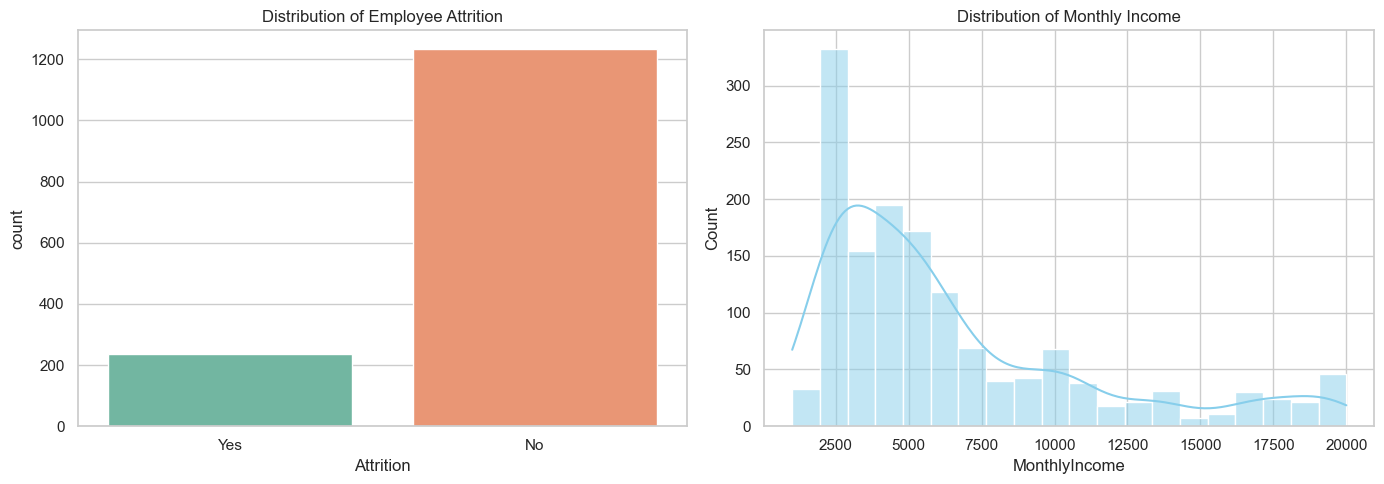

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Attrition Distribution
sns.countplot(x='Attrition', data=df_cleaned, ax=axes[0], palette='Set2')
axes[0].set_title('Distribution of Employee Attrition')

# Monthly Income Distribution
sns.histplot(df_cleaned['MonthlyIncome'], kde=True, ax=axes[1], color='skyblue')
axes[1].set_title('Distribution of Monthly Income')

plt.tight_layout()
plt.show()

**EDA Interpretations:**
- **Categorical**: The dataset is imbalanced regarding Attrition; most employees stay ('No' is frequent). The most common department is 'Research & Development'.
- **Numerical**: The average age is ~37 years. `MonthlyIncome` is highly right-skewed, indicating most employees earn below 10,000, while a few top-level employees earn significantly more (up to 19,999).

### 5. Statistical & Correlation Summary
Generating a correlation matrix for numerical attributes to identify strong, moderate, and weak relationships.

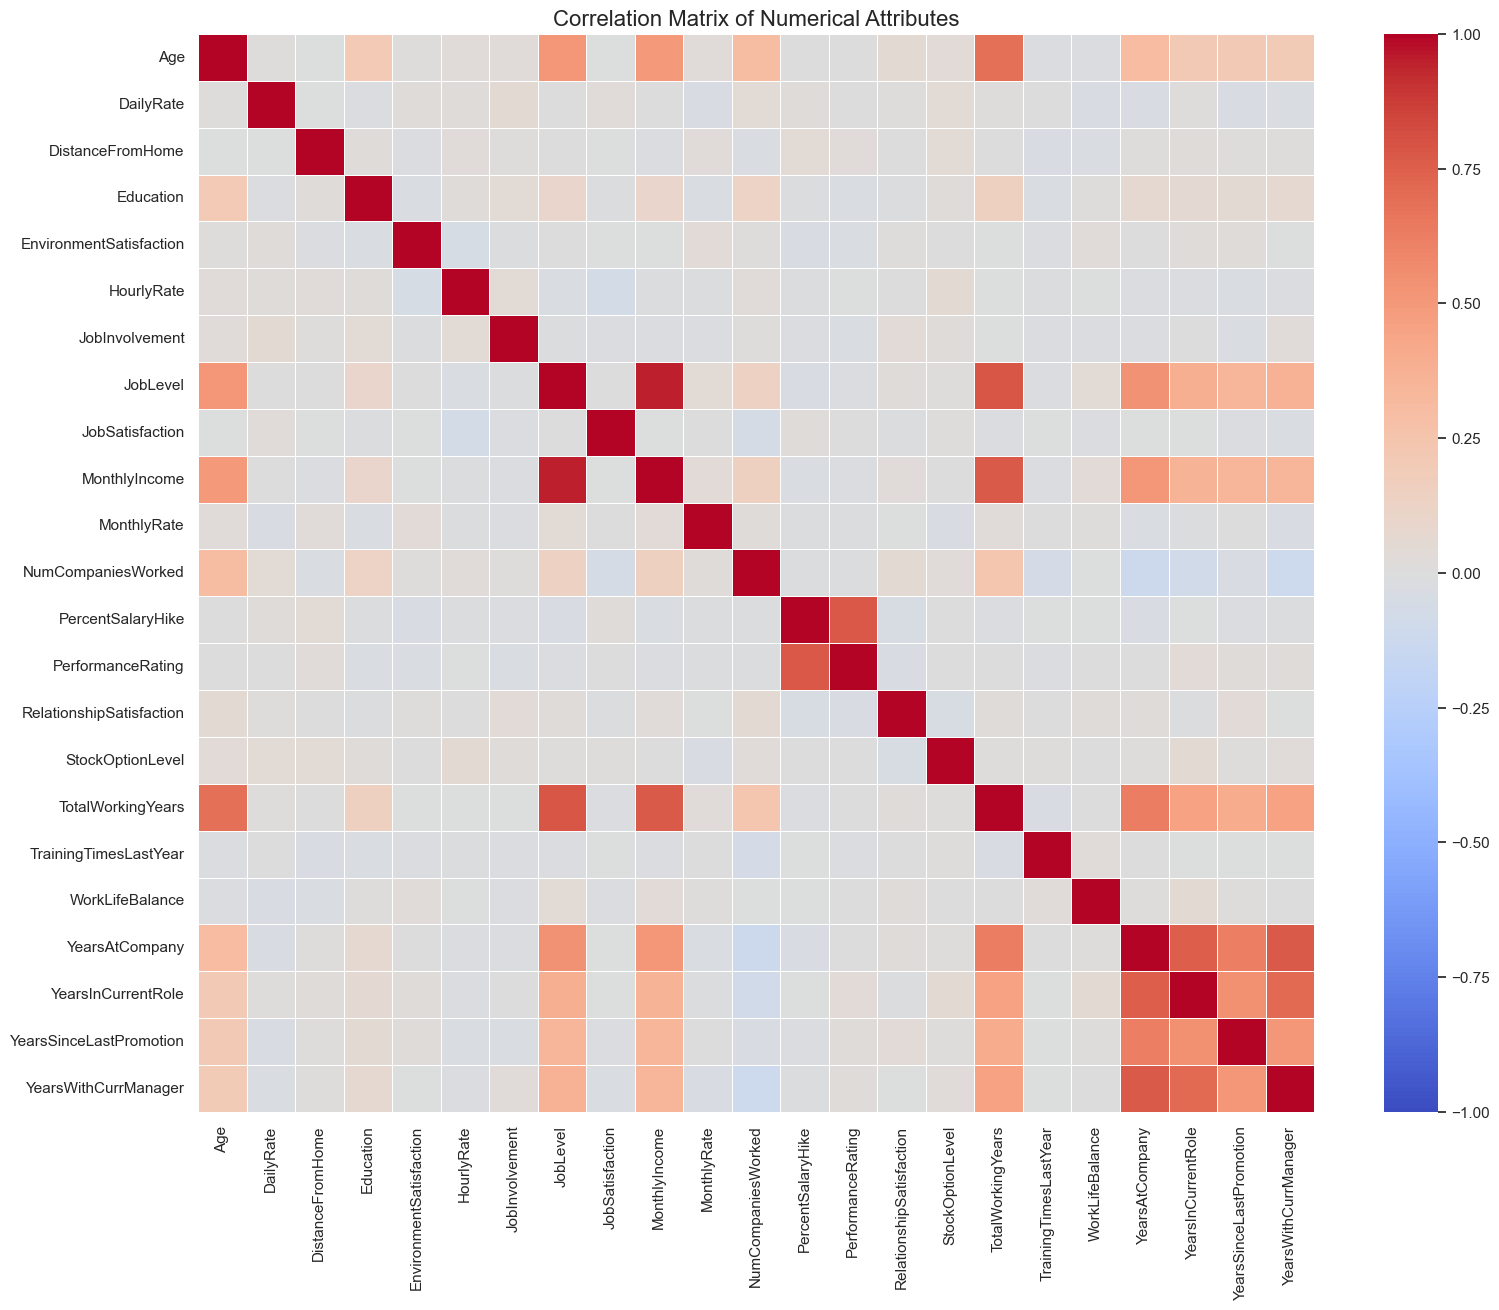

In [23]:
# Select only numerical attributes
numerical_cols = df_cleaned.select_dtypes(include=[np.number])

# Compute correlation matrix
corr_matrix = numerical_cols.corr()

# Plot the heatmap
plt.figure(figsize=(18, 14))
sns.heatmap(corr_matrix, annot=False, cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Correlation Matrix of Numerical Attributes', fontsize=16)
plt.show()

**Correlation Interpretations:**
- **Strong Positive Correlation**: `JobLevel` and `MonthlyIncome` (~0.95), which is expected as higher job levels typically offer higher salaries. `TotalWorkingYears` is also strongly correlated with `JobLevel` and `MonthlyIncome`.
- **Moderate Correlation**: `Age` shows a moderate positive correlation with `TotalWorkingYears` (~0.68).
- **Weak/No Correlation**: `DailyRate`, `HourlyRate`, and `MonthlyRate` show virtually no correlation with other variables or each other, which is an interesting observation indicating these rates might be determined by disparate external factors rather than tenure or level.
- **Unexpected/Interesting**: `YearsAtCompany` is strongly correlated with `YearsWithCurrManager` (~0.77) and `YearsInCurrentRole` (~0.76). However, `PerformanceRating` only has a notable relationship with `PercentSalaryHike` (~0.77), showing no significant link to `MonthlyIncome` or `JobSatisfaction`.

### 6. Group-based Correlation Analysis
Segmenting the dataset into multiple meaningful subsets based on `Department` and comparing correlation patterns.

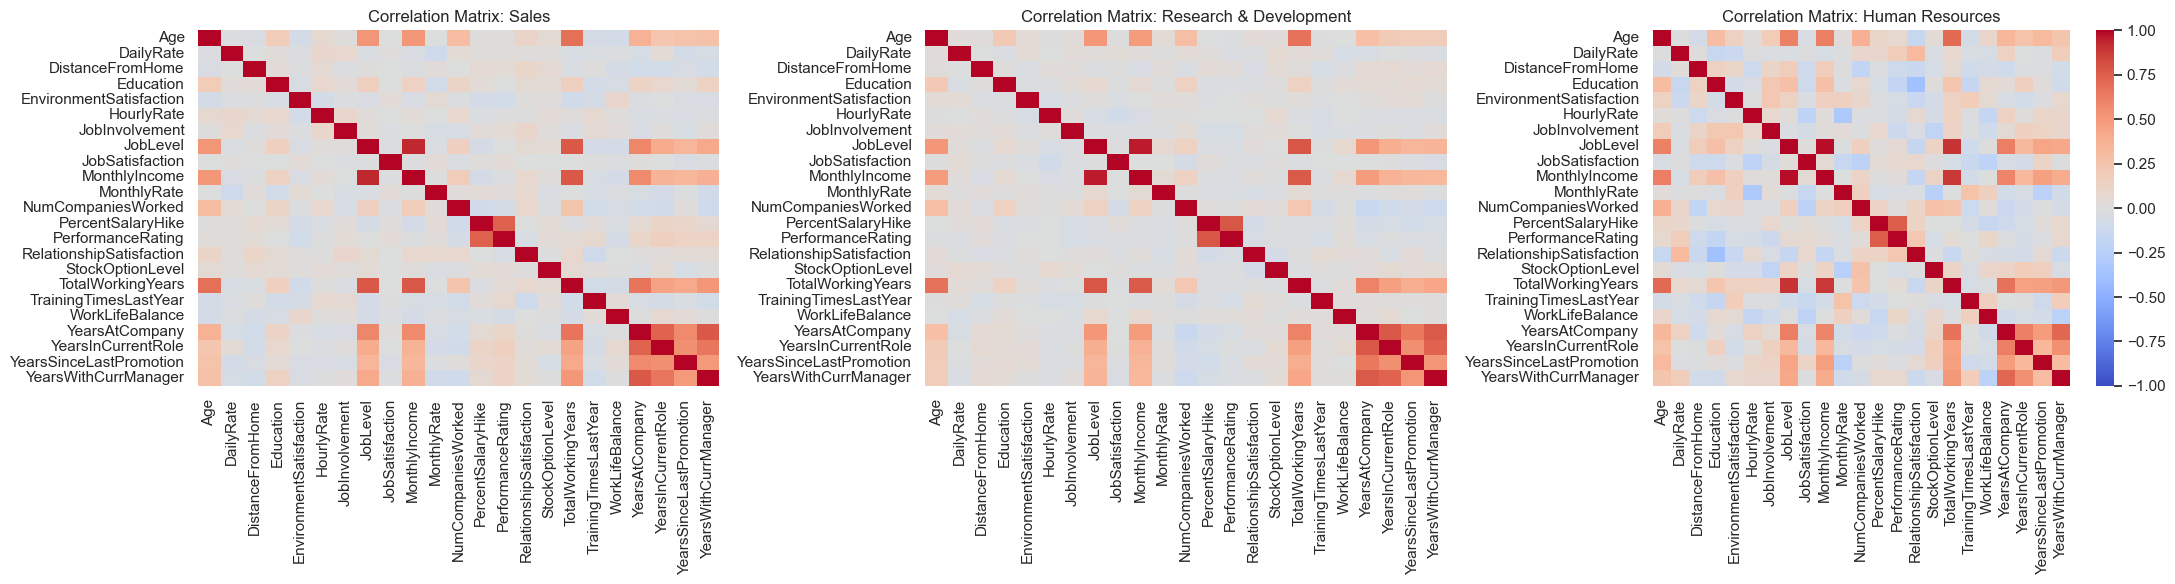

In [24]:
departments = df_cleaned['Department'].unique()
fig, axes = plt.subplots(1, len(departments), figsize=(22, 6))

for i, dept in enumerate(departments):
    # Subset data by department
    dept_data = df_cleaned[df_cleaned['Department'] == dept]
    dept_num = dept_data.select_dtypes(include=[np.number])
    
    # Calculate correlation matrix for the subset
    dept_corr = dept_num.corr()
    
    # Plot heatmap for the subset
    sns.heatmap(dept_corr, ax=axes[i], cmap='coolwarm', vmin=-1, vmax=1, cbar=(i == len(departments)-1))
    axes[i].set_title(f'Correlation Matrix: {dept}')

plt.tight_layout()
plt.show()

**Group-Based Correlation Interpretations (Similarities and Differences):**

- **Consistent Relationships (Similarities across all departments)**: Across Sales, Research & Development (R&D), and Human Resources (HR), the fundamental structural relationships remain stable. The strong correlation between `JobLevel`, `MonthlyIncome`, and `TotalWorkingYears` appears universally across all groups, validating that experience and hierarchical level consistently drive compensation regardless of the department.
- **Varying Relationships (Differences between subsets)**:
  - *HR vs. Sales/R&D*: In the HR department, we can observe slightly more variance in how `YearsInCurrentRole` correlates with `YearsWithCurrManager`. The correlation matrix for HR looks "noisier" in certain areas, likely due to the much smaller sample size of HR employees compared to R&D.
  - *Performance & Salary Hike*: The relationship between `PercentSalaryHike` and `PerformanceRating` remains strong across all, but there are subtle differences in how `TrainingTimesLastYear` relates to age or tenure between Sales and R&D.
  - *Domain-related explanation*: Sales relies heavily on immediate performance and commissions, while R&D is tenure and skill-based. Thus, tenure metrics (`YearsAtCompany`) in R&D show more consolidated strong correlation blocks with income compared to Sales, where turnover might be higher and compensation more dynamic.